In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV 
from sklearn.tree import DecisionTreeClassifier
from sklearn import metrics
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from statsmodels.stats.outliers_influence import variance_inflation_factor
import pandas as pd
from statsmodels.stats.outliers_influence import variance_inflation_factor
import funkcje
import umap

/home/michnal/miniforge3/envs/binf2/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Wczytanie danych i inspekcja

In [2]:
# Wczytanie danych i czyszczenie
df = pd.read_csv("../output/features/all_features.csv")

#Inspekcja danych ile mamy NA
df.isna().sum()


gbifID                        0
decimalLongitude              0
decimalLatitude               0
wc2.1_30s_bio_1               0
wc2.1_30s_bio_10              0
wc2.1_30s_bio_11              0
wc2.1_30s_bio_12              0
wc2.1_30s_bio_13              0
wc2.1_30s_bio_14              0
wc2.1_30s_bio_15              0
wc2.1_30s_bio_16              0
wc2.1_30s_bio_17              0
wc2.1_30s_bio_18              0
wc2.1_30s_bio_19              0
wc2.1_30s_bio_2               0
wc2.1_30s_bio_3               0
wc2.1_30s_bio_4               0
wc2.1_30s_bio_5               0
wc2.1_30s_bio_6               0
wc2.1_30s_bio_7               0
wc2.1_30s_bio_8               0
wc2.1_30s_bio_9               0
Aspect                       19
Curvature                    26
DEM                          13
NDVI                         14
EVI                          14
SAVI                         14
NDWI                         14
BSI                          14
Slope                        19
Snow_Dur

# DEM

In [3]:
#Usuwamy DEM aby uniezależnić model od wysokości, która jest silnie skorelowana z innymi warstwami
df = df.drop(columns="DEM")

## Bioclim 
BIOCLIM (Bioclimatic variables) to zestaw 19 globalnych zmiennych klimatycznych, wyprowadzonych z miesięcznych pomiarów temperatury i opadów. Zamiast prostych średnich, odzwierciedlają one uwarunkowania biologiczne i środowiskowe istotne dla życia organizmów.

        bio1="Annual Mean Temperature (°C)",
        bio2="Mean Diurnal Range",
        bio3="Isothermality",
        bio4="Temperature Seasonality",
        bio5="Max Temp Warmest Month",
        bio6="Min Temp Coldest Month",
        bio7="Temp Annual Range",
        bio8="Mean Temp Wettest Quarter",
        bio9="Mean Temp Driest Quarter",
        bio10="Mean Temp Warmest Quarter",
        bio11="Mean Temp Coldest Quarter",
        bio12="Annual Precipitation (mm)",
        bio13="Precipitation Wettest Month",
        bio14="Precipitation Driest Month",
        bio15="Precipitation Seasonality",
        bio16="Precipitation Wettest Quarter",
        bio17="Precipitation Driest Quarter",
        bio18="Precipitation Warmest Quarter",
        bio19="Precipitation Coldest Quarter"
        
Są one mocno z sobą skorelowane. Będziemy musieli wybrać do modelu odpowiednie.

            feature        VIF
0  wc2.1_30s_bio_19  57.695369
1  wc2.1_30s_bio_18  43.115827
2  wc2.1_30s_bio_15  23.433833
3   wc2.1_30s_bio_6  22.992355
4  wc2.1_30s_bio_10  18.967996
5   wc2.1_30s_bio_9  10.043593


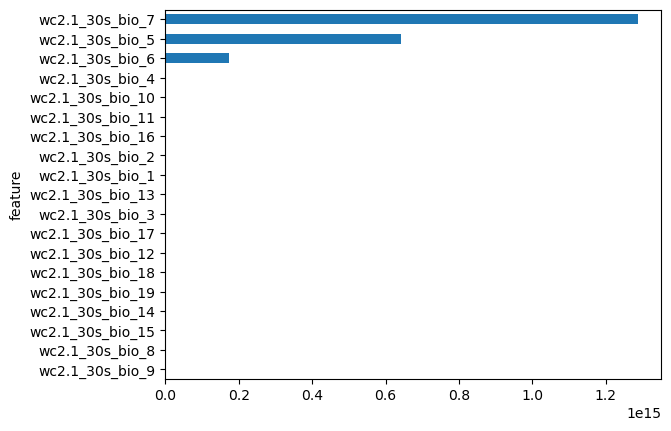

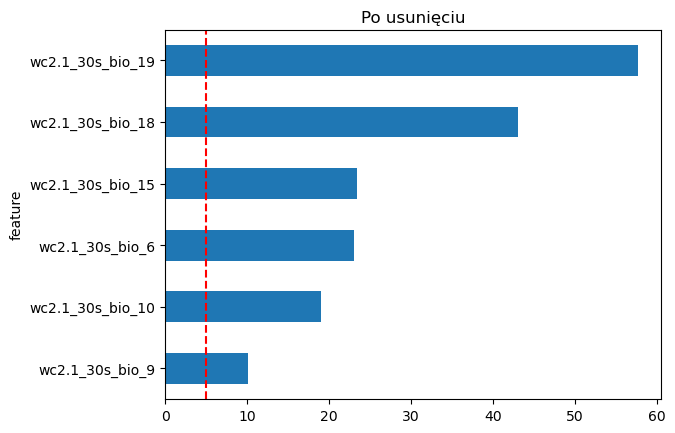

In [4]:


def calculate_vif_wc(df):
    vif_data = pd.DataFrame()
    wybrane_kolumny = df.columns[df.columns.str.contains("wc", case=False)]
    features = df[wybrane_kolumny]
    vif_data["feature"] = features.columns
    vif_data["VIF"] = [variance_inflation_factor(features.values, i) for i in range(features.shape[1])]
    vif_df = vif_data.sort_values(by="VIF", ascending=False).reset_index(drop=True)
    return vif_df

# Sprawdzamy VIF

vif_df = calculate_vif_wc(df)
vif_df.sort_values(by="VIF").plot(
    kind="barh", x="feature", y="VIF", legend=False
)
#Wyrzucamy warstwy bioklimatyczne o njwiększym VIF ale takie które mają sens biologiczny
df_wc=df.drop(columns=["wc2.1_30s_bio_7", 
                       "wc2.1_30s_bio_1", 
                       "wc2.1_30s_bio_12", 
                       "wc2.1_30s_bio_4", 
                       "wc2.1_30s_bio_5", 
                       "wc2.1_30s_bio_16",
                       "wc2.1_30s_bio_11",
                       "wc2.1_30s_bio_14",
                       "wc2.1_30s_bio_13",
                       "wc2.1_30s_bio_3",
                       "wc2.1_30s_bio_17",
                       "wc2.1_30s_bio_8",
                       "wc2.1_30s_bio_2"])
vif_df = calculate_vif_wc(df_wc)
print(vif_df)
vif_df.sort_values(by="VIF").plot(kind="barh", x="feature", y="VIF", legend=False, title = "Po usunięciu")
plt.axvline(x=5, color="r", linestyle="--")
df=df_wc

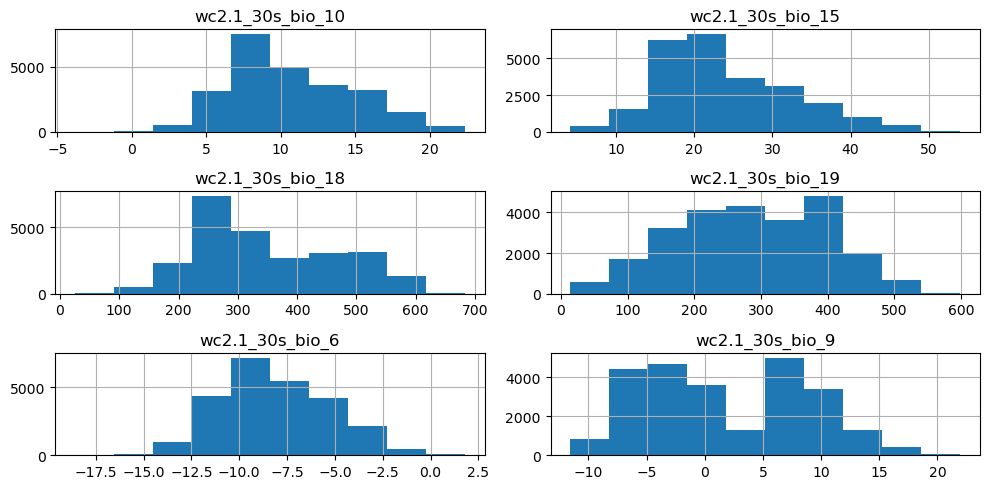

In [5]:
#Kolumny WC
wybrane_kolumny = df.columns[df.columns.str.contains("wc", case=False)]

#Histogramy dla WC
df[wybrane_kolumny].hist(bins=10, figsize=(10, 5))

#Wyświetlenie wykresu
plt.tight_layout()
plt.show()

## Snow Duration
Liczba dni w roku w których wystepuje pokrywa śnieżna. Dane z satelity Sentiel-1, pobrane z GEE.

<Axes: >

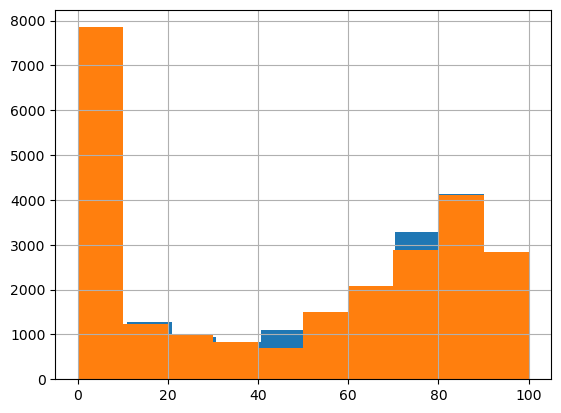

In [6]:
df["Snow_Duration_Pct"].hist()
df['Snow_Duration_Pct'] = df['Snow_Duration_Pct'].fillna(0)
#Uzupełnienie brakujących wartości w kolumnie "Snow_Duration_Pct" wartością 0. 
#"0" biologicznie oznacza brak opadów więc jest to legalne
df["Snow_Duration_Pct"].hist()

## Soil
Warstwy glebowe sa ważne bo te rośliny rosnać często na wapieniu lub granicie

In [7]:
df.isna().sum()
#Sporo warstw glebowych ma NA. Dzieje się tak jeśli występują na głównie na skale


gbifID                       0
decimalLongitude             0
decimalLatitude              0
wc2.1_30s_bio_10             0
wc2.1_30s_bio_15             0
wc2.1_30s_bio_18             0
wc2.1_30s_bio_19             0
wc2.1_30s_bio_6              0
wc2.1_30s_bio_9              0
Aspect                      19
Curvature                   26
NDVI                        14
EVI                         14
SAVI                        14
NDWI                        14
BSI                         14
Slope                       19
Snow_Duration_Pct            0
Soil_Clay                  819
Soil_Organic_Carbon        818
Soil_pH                    819
Soil_Sand                  819
Topo_Solar_Radiation_MJ     19
TRI                         13
TWI                         19
dtype: int64

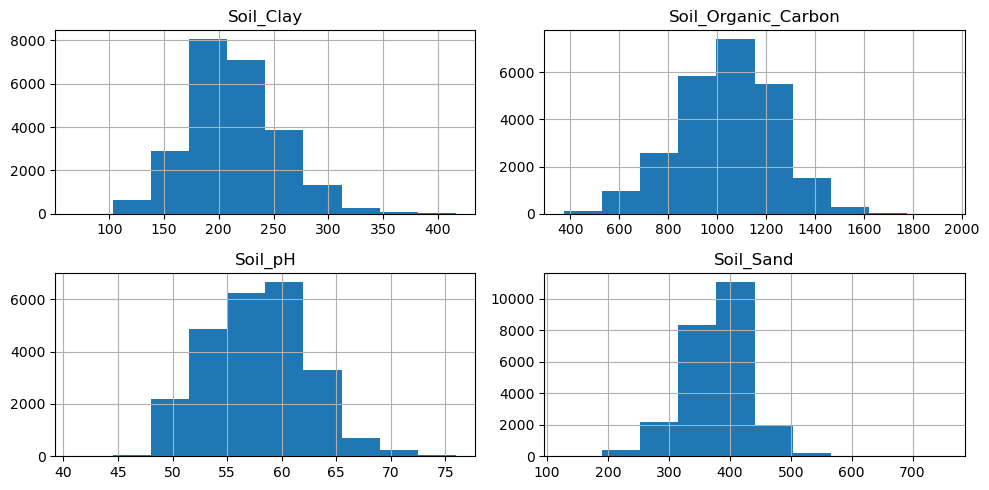

In [8]:
#Kolumny Soil
wybrane_kolumny = df.columns[df.columns.str.contains("soil", case=False)]

#Histogramy dla WC
df[wybrane_kolumny].hist(bins=10, figsize=(10, 5))

#Wyświetlenie wykresu
plt.tight_layout()
plt.show()

##

## Wskaźniki ekologiczne
1. NDVI (Normalized Difference Vegetation Index) wkaźnik gętosći zieleni. Od 1 do -1 Bujna roślinność 1 brak -1.
2. EVI (Enhanced Vegetation Index) ulepsozny NDVI porpzez dodanie światła niebieskiego
3. SAVI (Soil-Adjusted Vegetation Index) 
4. BSI (Bare Soil Index) wartość gołośći ziemi


VIF przed usunięciem:
   feature           VIF
0    SAVI  1.855178e+07
1    NDVI  1.855079e+07
2     BSI  2.818329e+00
3     EVI  1.056540e+00


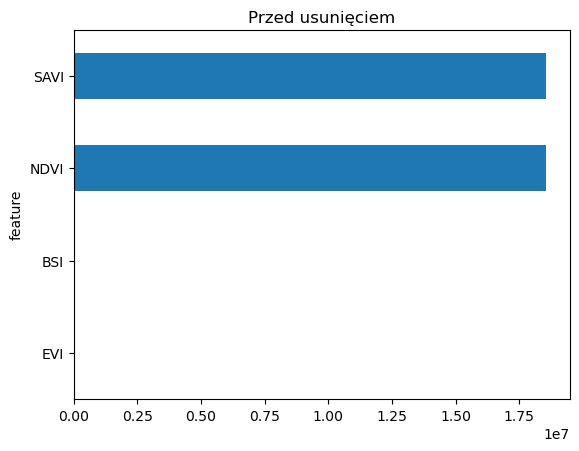

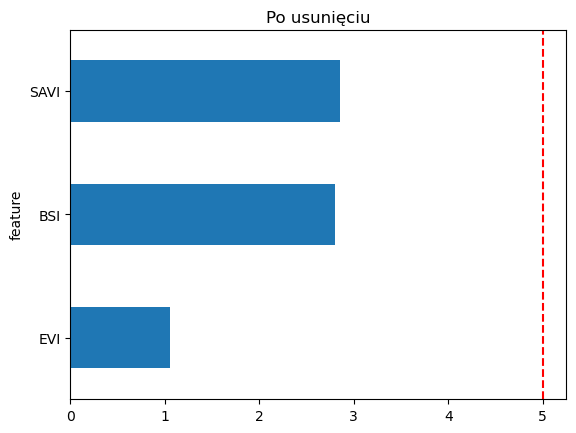

In [9]:
wskazniki_ekologiczne = ["NDVI", "EVI", "SAVI", "BSI"]


def calculate_vif_eco(data_frame, lista_kolumn):
    vif_data = pd.DataFrame()

    # Wycinamy tylko te, które istnieją w df, i usuwamy braki danych
    istniejace_kolumny = [col for col in lista_kolumn if col in data_frame.columns]
    X = data_frame[istniejace_kolumny].dropna()

    vif_data["feature"] = X.columns
    vif_data["VIF"] = [
        variance_inflation_factor(X.values, i) for i in range(X.shape[1])
    ]
    return vif_data.sort_values(by="VIF", ascending=False).reset_index(
        drop=True
    )


df_eco = df
vif_przed = calculate_vif_eco(df, wskazniki_ekologiczne)
print("VIF przed usunięciem:\n", vif_przed)
vif_przed.sort_values(by="VIF").plot(kind="barh", x="feature", y="VIF", legend=False, title="Przed usunięciem")
plt.axvline(x=5, color="r", linestyle="--")
plt.show()

#Usuwmay NVDI bo to defatko to samo 
df_cleaned = df_eco.drop(columns=["NDVI", "NDWI"])
vif_po = calculate_vif_eco(df_cleaned, wskazniki_ekologiczne)

#Wykres po
vif_po.sort_values(by="VIF").plot(kind="barh", x="feature", y="VIF", legend=False, title="Po usunięciu")
plt.axvline(x=5, color="r", linestyle="--")
df=df_cleaned


Macierz korelacji:
                         wc2.1_30s_bio_10  wc2.1_30s_bio_15  wc2.1_30s_bio_18  \
wc2.1_30s_bio_10                 1.000000          0.468824          0.026731   
wc2.1_30s_bio_15                 0.468824          1.000000          0.203179   
wc2.1_30s_bio_18                 0.026731          0.203179          1.000000   
wc2.1_30s_bio_19                -0.398184         -0.698694         -0.005984   
wc2.1_30s_bio_6                  0.934170          0.315120         -0.028592   
wc2.1_30s_bio_9                  0.189260         -0.372856         -0.578466   
Aspect                          -0.019123         -0.012898         -0.021182   
Curvature                       -0.146130         -0.076862          0.032825   
EVI                              0.066018          0.043745          0.016175   
SAVI                             0.574369          0.410769          0.215376   
BSI                             -0.563128         -0.414649         -0.185942   
Slope    

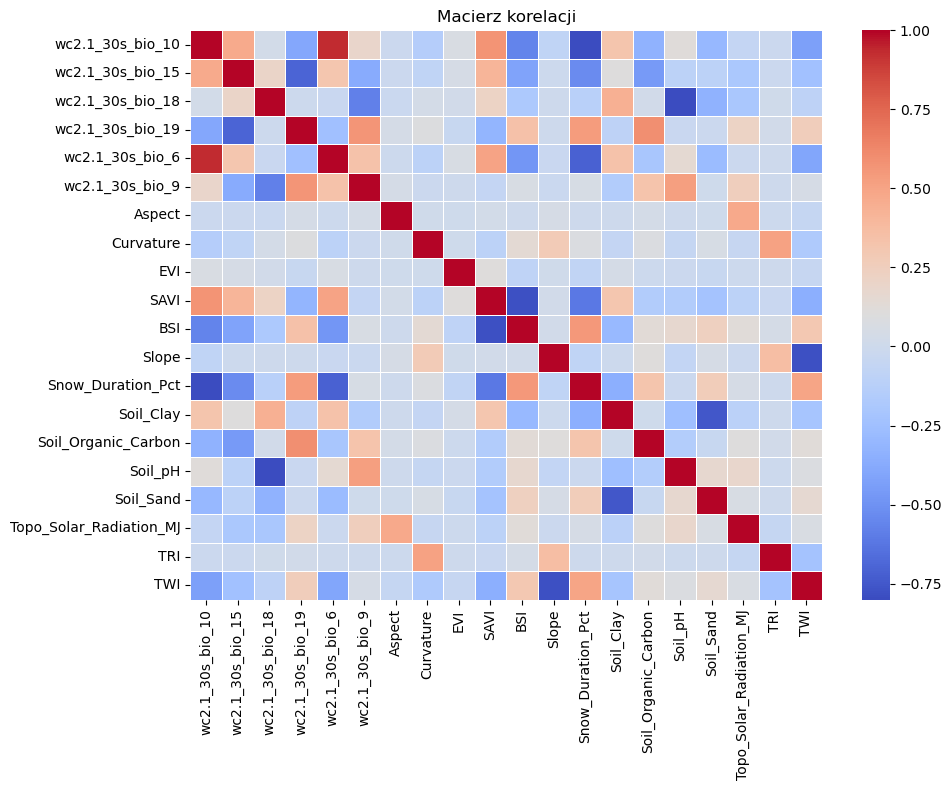

In [10]:
#Wybór tylko numerycznych kolumn
numeric_cols = df.select_dtypes(include=[np.number]).columns

#Wykluczenie zbanowanych kolumn
banned_cols = ["decimalLongitude", "decimalLatitude"]
features_cols = [col for col in numeric_cols if col not in banned_cols]

#Obliczenie macierzy korelacji dla odfiltrowanych danych
macierz_korelacji = df[features_cols].corr()
print("Macierz korelacji:")
print(macierz_korelacji)

#Generowanie heatmapy
plt.figure(figsize=(10, 8))
sns.heatmap(
    macierz_korelacji, 
    cmap='coolwarm', 
    linewidths=0.5 
)
plt.title("Macierz korelacji")
plt.tight_layout()
plt.show()


In [11]:
# Usuwanie wierszy z brakami danych (NaN)
df = df.dropna()

# Konwersja kolumny na tekst
df["gbifID"] = df["gbifID"].astype(str)

# Tworzenie kolumny z informacją o pseudoabsencji (0 = pseudo, 1 = prawdziwa obecność)
df["true_present"] = df["gbifID"].str.contains("pseudo", case=True).map({True: 0, False: 1})

#Filtrowanie tylko wierszy z pseudoabsencją
df_pseudo_absence = df[df["true_present"] == 0]
df_pseudo_absence.to_csv("../output/features/pseudo_absence.csv", index=False)

#Definiowanie X (odrzucamy ID, współrzędne oraz nową kolumnę target)
columns_to_drop = ["gbifID", "decimalLongitude", "decimalLatitude", "true_present"]
X = df.drop(columns=columns_to_drop)


# Random Forest

In [12]:
# 1. Definiowanie zmiennej objaśnianej (y) - poprawny wybór kolumny target
y = df["true_present"]

# 2. Definiowanie zmiennych objaśniających (X) - ID, współrzędne oraz target
columns_to_drop = ["gbifID", "decimalLongitude", "decimalLatitude", "true_present"]
X = df.drop(columns=columns_to_drop, errors="ignore")

# 3. Podział na zbiór treningowy i testowy
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=0
)


In [13]:
y

0        1
1        1
2        1
3        1
4        1
        ..
25044    0
25045    0
25046    0
25047    0
25048    0
Name: true_present, Length: 24148, dtype: int64

In [14]:
#siatka parametrów do sprawdzenia
param_grid = {
    'criterion': ['gini'],
    'max_depth': [None], 
    'min_samples_split': [2],     
    'max_features': [None],
    'class_weight': [None]
}

#konfiguracja grid
grid_search = GridSearchCV(estimator=DecisionTreeClassifier(random_state=0), 
                           param_grid=param_grid, 
                           cv=5, 
                           n_jobs=5, 
                           verbose=1, 
                           scoring='accuracy')

# grid serach
grid_search.fit(X_train, y_train)

# najlepsze
print(f"Najlepsze parametry: {grid_search.best_params_}")
print(f"Najlepszy wynik (accuracy): {grid_search.best_score_}")

# zapis
best_tree = grid_search.best_estimator_

#Sprawdzenie na zbiorze testowym
y_pred = best_tree.predict(X_test)
print(metrics.classification_report(y_test, y_pred))

Fitting 5 folds for each of 1 candidates, totalling 5 fits
Najlepsze parametry: {'class_weight': None, 'criterion': 'gini', 'max_depth': None, 'max_features': None, 'min_samples_split': 2}
Najlepszy wynik (accuracy): 0.8264805237762716
              precision    recall  f1-score   support

           0       0.83      0.81      0.82      3571
           1       0.82      0.84      0.83      3674

    accuracy                           0.82      7245
   macro avg       0.83      0.82      0.82      7245
weighted avg       0.83      0.82      0.82      7245



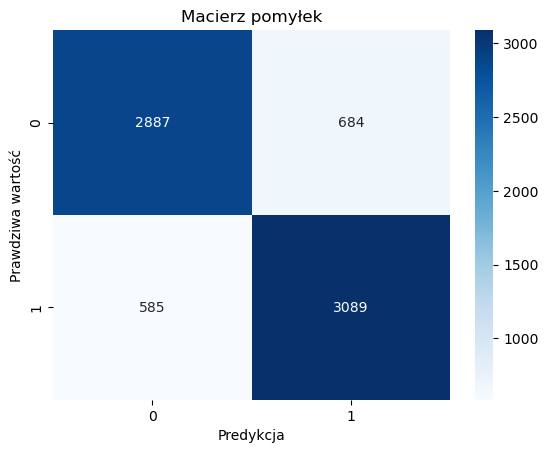

In [15]:
#Macierz pomyłek
cm = metrics.confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predykcja')
plt.ylabel('Prawdziwa wartość')
plt.title('Macierz pomyłek')
plt.show()

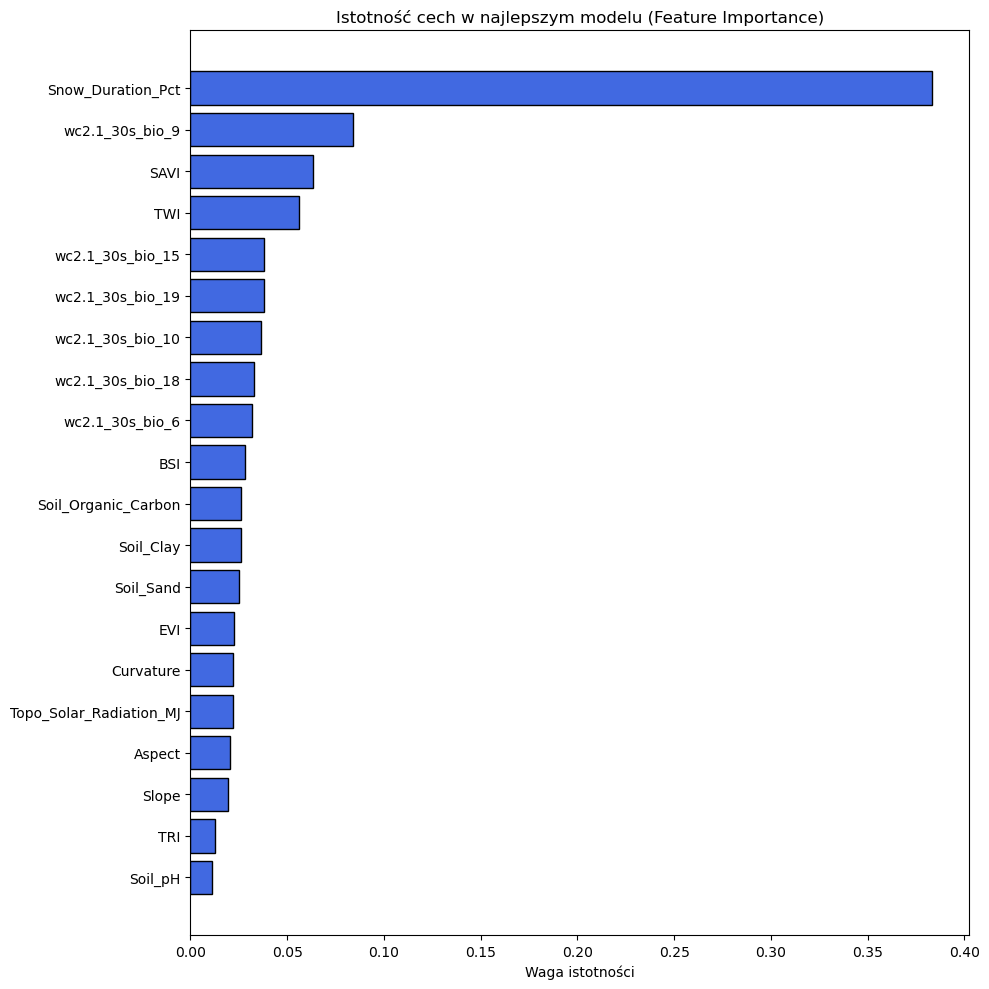

In [16]:
# Pobranie istotności cech z najlepszego estymatora Grid Search
# Zastąp 'grid_search' nazwą swojej zmiennej z GridSearchCV
najlepszy_model = grid_search.best_estimator_
importances = najlepszy_model.feature_importances_

# Tworzenie DataFrame z wynikami
istotnosc_df = pd.DataFrame({
    'Cecha': X.columns,
    'Istotnosc': importances
}).sort_values(by='Istotnosc', ascending=True)

# Wykres poziomy
plt.figure(figsize=(10, 10))
plt.barh(istotnosc_df['Cecha'], istotnosc_df['Istotnosc'], color='royalblue', edgecolor='black')
plt.title('Istotność cech w najlepszym modelu (Feature Importance)')
plt.xlabel('Waga istotności')
plt.tight_layout()
plt.show()


# RF

In [17]:
from sklearn.ensemble import RandomForestClassifier
#siatka parametrów do sprawdzenia
param_grid = {
    "n_estimators": [200],  
    "criterion": ["gini"],
    "max_depth": [None],  # Głębokość pojedynczych drzew
    #"min_samples_split": [2, 5, 10],  # Min. liczba próbek do podziału węzła
    "max_features": ["sqrt"],  
    "class_weight": ["balanced"],
}

#konfiguracja grid
grid_search = GridSearchCV(
    estimator=RandomForestClassifier(random_state=0, n_jobs=-1),
    param_grid=param_grid,
    cv=3,
    n_jobs=5,
    verbose=1,
    scoring="accuracy",
)

# grid serach
grid_search.fit(X_train, y_train)

# najlepsze
print(f"Najlepsze parametry: {grid_search.best_params_}")
print(f"Najlepszy wynik (accuracy): {grid_search.best_score_}")

# zapis
best_tree = grid_search.best_estimator_

#Sprawdzenie na zbiorze testowym
y_pred = best_tree.predict(X_test)
print(metrics.classification_report(y_test, y_pred))



Fitting 3 folds for each of 1 candidates, totalling 3 fits
Najlepsze parametry: {'class_weight': 'balanced', 'criterion': 'gini', 'max_depth': None, 'max_features': 'sqrt', 'n_estimators': 200}
Najlepszy wynik (accuracy): 0.8719163354866727
              precision    recall  f1-score   support

           0       0.89      0.84      0.87      3571
           1       0.85      0.90      0.88      3674

    accuracy                           0.87      7245
   macro avg       0.87      0.87      0.87      7245
weighted avg       0.87      0.87      0.87      7245



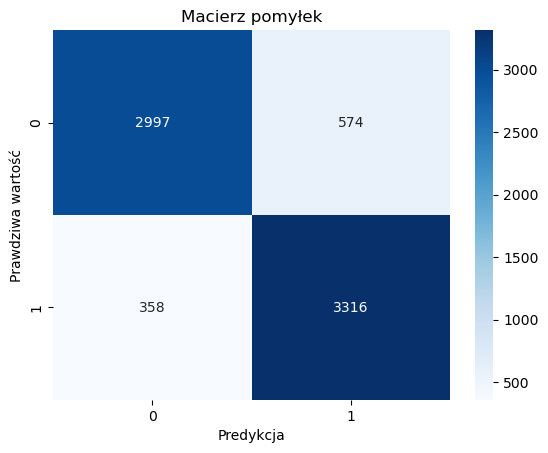

In [18]:
#Macierz pomyłek
cm = metrics.confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predykcja')
plt.ylabel('Prawdziwa wartość')
plt.title('Macierz pomyłek')
plt.show()

# PCA

--- ISTOTNOŚĆ (WSPÓŁCZYNNIKI ODWZOROWANIA) ZMIENNYCH NA OSIACH PCA ---
                           PC1    PC2    PC3    PC4    PC5    PC6    PC7  \
wc2.1_30s_bio_10         0.213  0.420 -0.163 -0.119 -0.098  0.167  0.063   
wc2.1_30s_bio_15         0.313 -0.059 -0.051 -0.360  0.000  0.159  0.044   
wc2.1_30s_bio_18         0.377 -0.173  0.027  0.300  0.099 -0.053  0.097   
wc2.1_30s_bio_19        -0.256  0.240 -0.050  0.443 -0.015 -0.055  0.038   
wc2.1_30s_bio_6          0.149  0.452 -0.122 -0.024 -0.092  0.188  0.082   
wc2.1_30s_bio_9         -0.296  0.401 -0.112  0.068 -0.105  0.081 -0.012   
Aspect                  -0.037  0.072 -0.046 -0.058  0.697 -0.048  0.249   
Curvature                0.057  0.112  0.386  0.015 -0.114  0.004  0.580   
EVI                      0.021  0.027 -0.017 -0.002  0.002 -0.113  0.102   
SAVI                     0.239  0.163 -0.275 -0.018 -0.059 -0.492  0.044   
BSI                     -0.204 -0.149  0.272  0.021  0.066  0.551 -0.024   
Slope            

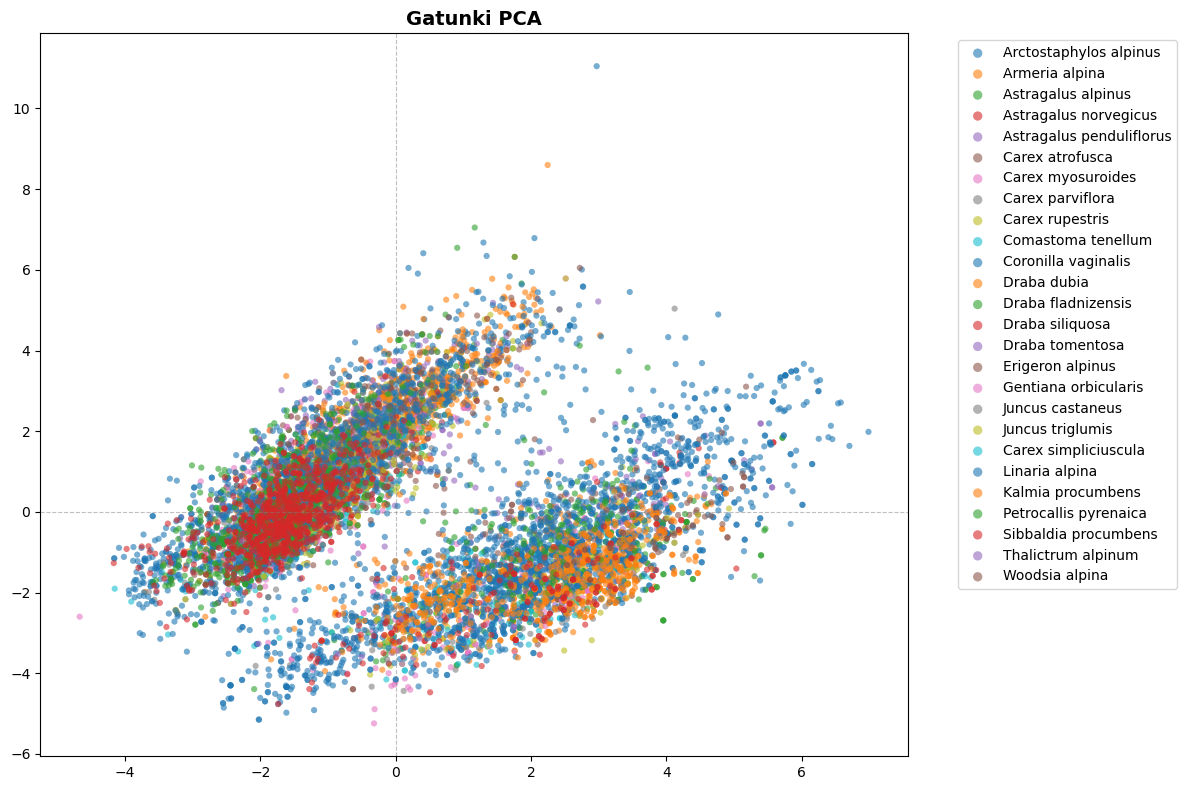

In [19]:
#informacje o gatunkach
meta =pd.read_csv("../output/final_data/merged_all_species.csv")

# Konwersja kolumny gbifID na tekst w obu ramkach
df['gbifID'] = df['gbifID'].astype(str)
meta['gbifID'] = meta['gbifID'].astype(str)

#przygotowanie danych
df_full = pd.merge(df, meta[["gbifID", "species"]], on="gbifID", how="inner")

# Ignorujemy kolumny geograficzne i identyfikacyjne w analizie cech środowiskowych
banned_cols = ["gbifID", "species", "decimalLongitude", "decimalLatitude"]
features_cols = [col for col in df.columns if col not in banned_cols]

df_clean = df_full.dropna(subset=features_cols).reset_index(drop=True)
X = df_clean[features_cols]
y_species = df_clean["species"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

#PCA z 9 składowymi, żeby mieć pełny obraz wpływu cech na przestrzeń cech
pca = PCA(n_components=9)
X_pca = pca.fit_transform(X_scaled)


# Obliczamy ładunki (loadings) - wpływ każdej zmiennej na PC1 i PC2
loadings = pd.DataFrame(
    pca.components_.T, columns=[f"PC{i+1}" for i in range(9)], index=features_cols
)

print("--- ISTOTNOŚĆ (WSPÓŁCZYNNIKI ODWZOROWANIA) ZMIENNYCH NA OSIACH PCA ---")
print(loadings.round(3))

#wykres PCA dla gatunków
plt.figure(figsize=(12, 8))

# Rysujemy punkty dla każdego gatunku osobno na jednym wykresie (plt)
for species_name in y_species.unique():
    mask = y_species == species_name
    plt.scatter(
        X_pca[mask, 0],
        X_pca[mask, 1],
        label=species_name,
        alpha=0.6,
        s=20,
        edgecolors="none",
    )

plt.title(
    "Gatunki PCA",
    fontsize=14,
    fontweight="bold",
)

# Przemieszczamy legendę poza wykres, żeby nie zasłaniała punktów przy wielu gatunkach
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", markerscale=1.5)
plt.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)
plt.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.5)

plt.tight_layout()
plt.show()

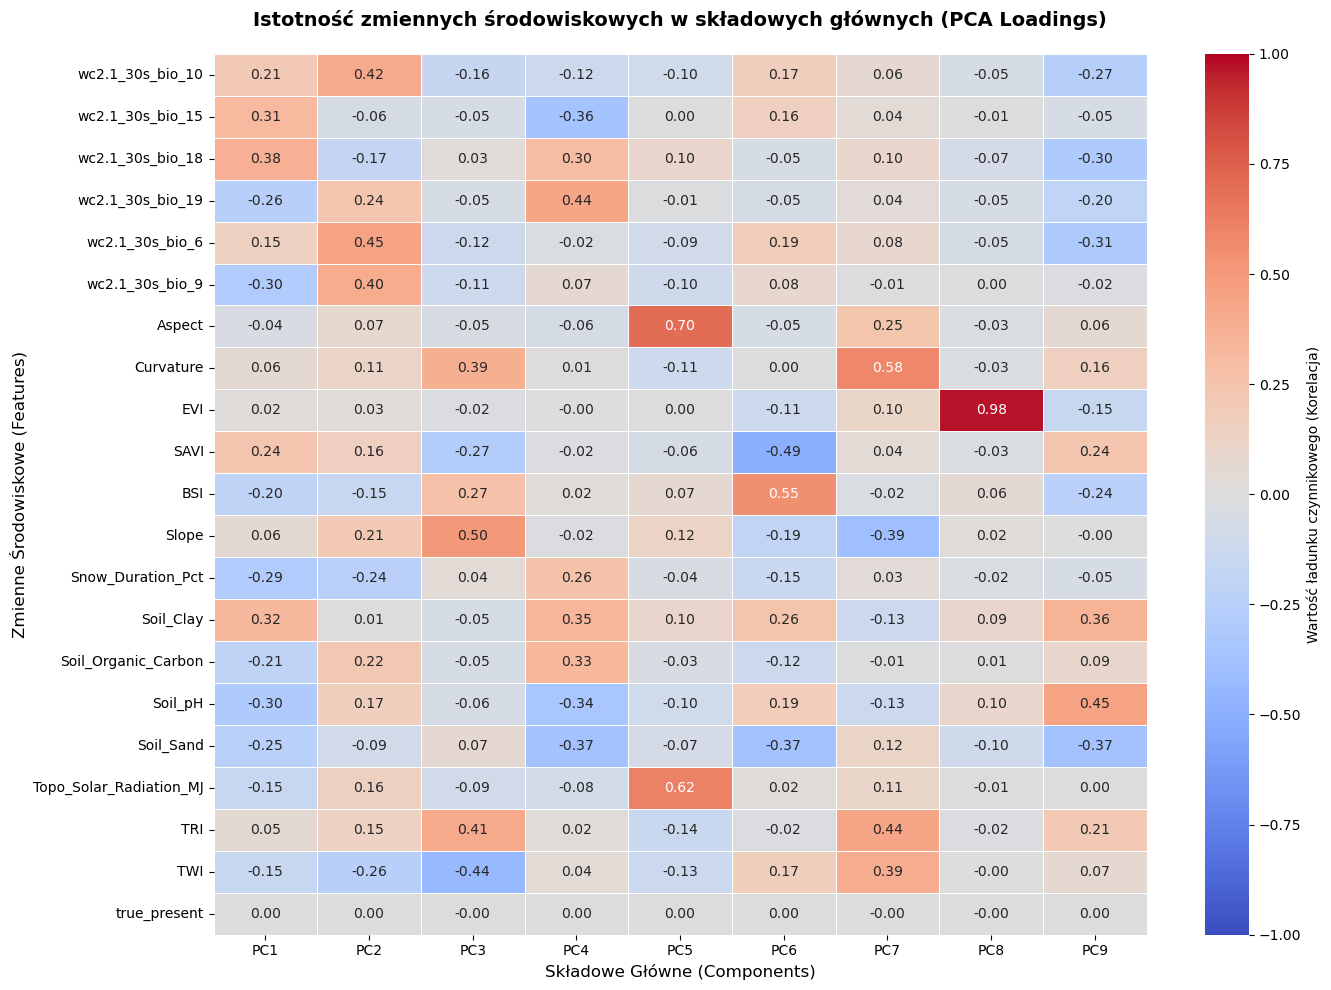

In [20]:
# HEATMAPA ŁADUNKÓW CZYNNIKOWYCH (LOADINGS)

plt.figure(figsize=(14, 10))

sns.heatmap(
    loadings,
    annot=True,  # Wyświetla wartości liczbowe w kwadratach
    fmt=".2f",  # Zaokrąglenie do 2 miejsc po przecinku
    cmap="coolwarm",
    vmin=-1.0,
    vmax=1.0,
    linewidths=0.5,  # Delikatne linie siatki separujące komórki
    cbar_kws={"label": "Wartość ładunku czynnikowego (Korelacja)"},
)

plt.title(
    "Istotność zmiennych środowiskowych w składowych głównych (PCA Loadings)",
    fontsize=14,
    fontweight="bold",
    pad=20,
)
plt.xlabel("Składowe Główne (Components)", fontsize=12)
plt.ylabel("Zmienne Środowiskowe (Features)", fontsize=12)

# Rotacja etykiet, żeby tekst na siebie nie nachodził
plt.xticks(rotation=0)
plt.yticks(rotation=0)

plt.tight_layout()
plt.show()

# Klastrowanie na east west

Cluster
West    7997
East    4168
Name: count, dtype: int64


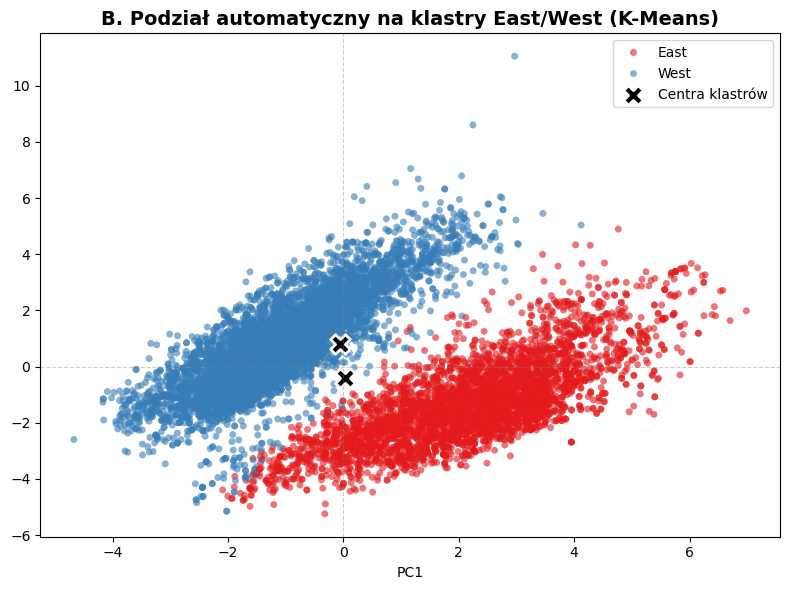

In [21]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans

#Klastrowanie k-means
kmeans = KMeans(n_clusters=2, init="k-means++", random_state=42)
df_clean["Cluster"] = kmeans.fit_predict(X_scaled)

# MAPOWANIE NAZW: 1 -> West, 0 -> East
# Zmieniamy typ na tekstowy, żeby wykres i tabela były czytelne
mapa_nazw = {1: "West", 0: "East"}
df_clean["Cluster"] = df_clean["Cluster"].map(mapa_nazw)

print(df_clean["Cluster"].value_counts())

# --- INICJALIZACJA JEDNEGO WYKRESU ---
plt.figure(figsize=(8, 6))
ax2 = plt.subplot(1, 1, 1)

# Prawy wykres: Wynik klastrowania z nowymi nazwami
# seaborn (sns) automatycznie ogarnie tekstową legendę dla "West" i "East"
scatter_clusters = sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df_clean["Cluster"],
    palette="Set1",  # Kolory dla grup
    alpha=0.6,
    s=25,
    ax=ax2,
    edgecolor="none",
)

# Dodajemy centra klastrów
centroids = kmeans.cluster_centers_
ax2.scatter(
    centroids[:, 0],
    centroids[:, 1],
    marker="X",
    s=200,
    linewidths=2,
    color="black",
    edgecolors="white",
    label="Centra klastrów",
)

ax2.set_title(
    "B. Podział automatyczny na klastry East/West (K-Means)",
    fontsize=14,
    fontweight="bold",
)
ax2.set_xlabel("PC1")
ax2.axhline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.4)
ax2.axvline(0, color="gray", linestyle="--", linewidth=0.8, alpha=0.4)

# Prosta legenda (Seaborn automatycznie dodał West i East, dorzucamy tylko info o centrach)
ax2.legend(loc="upper right")

plt.tight_layout()
plt.show()

# LDA

URUCHAMIAM LDA DLA KOLUMNY: 'SPECIES'
Liczba unikalnych grup/klas: 26
Wybrana liczba składowych LDA: 2


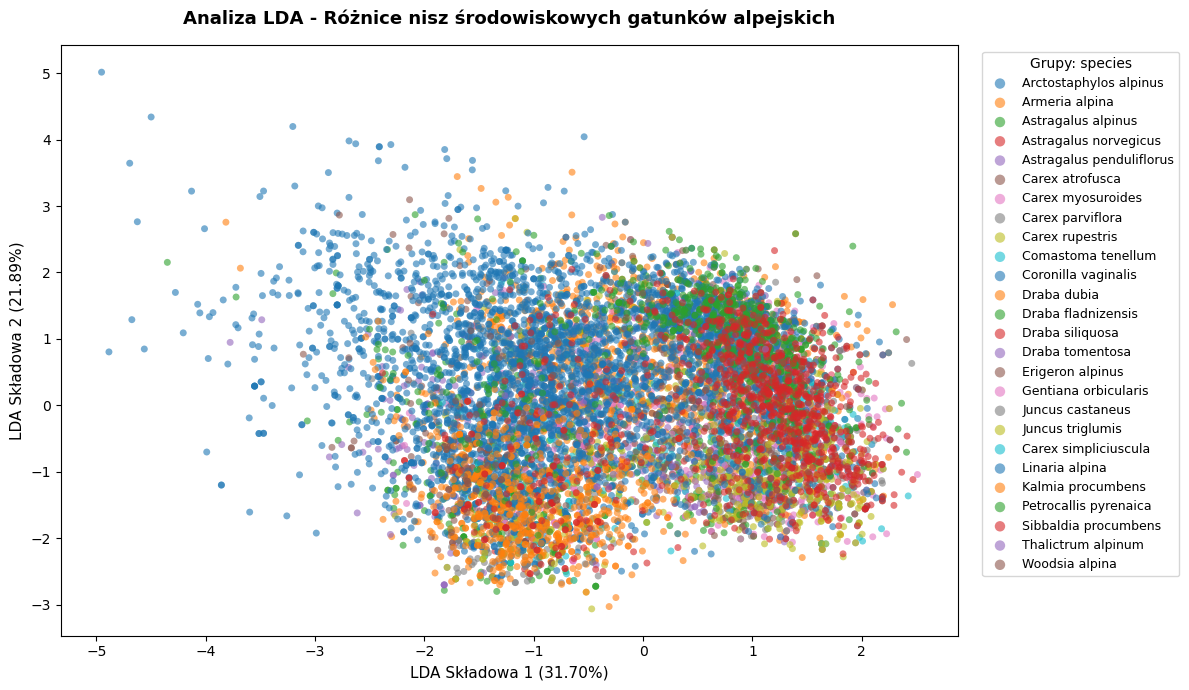


--- WYJAŚNIONA ZMIENNOŚĆ MIĘDZYKLASOWA ---
Składowa 1 wyjaśnia: 31.70% zmienności między grupami
Składowa 2 wyjaśnia: 21.89% zmienności między grupami


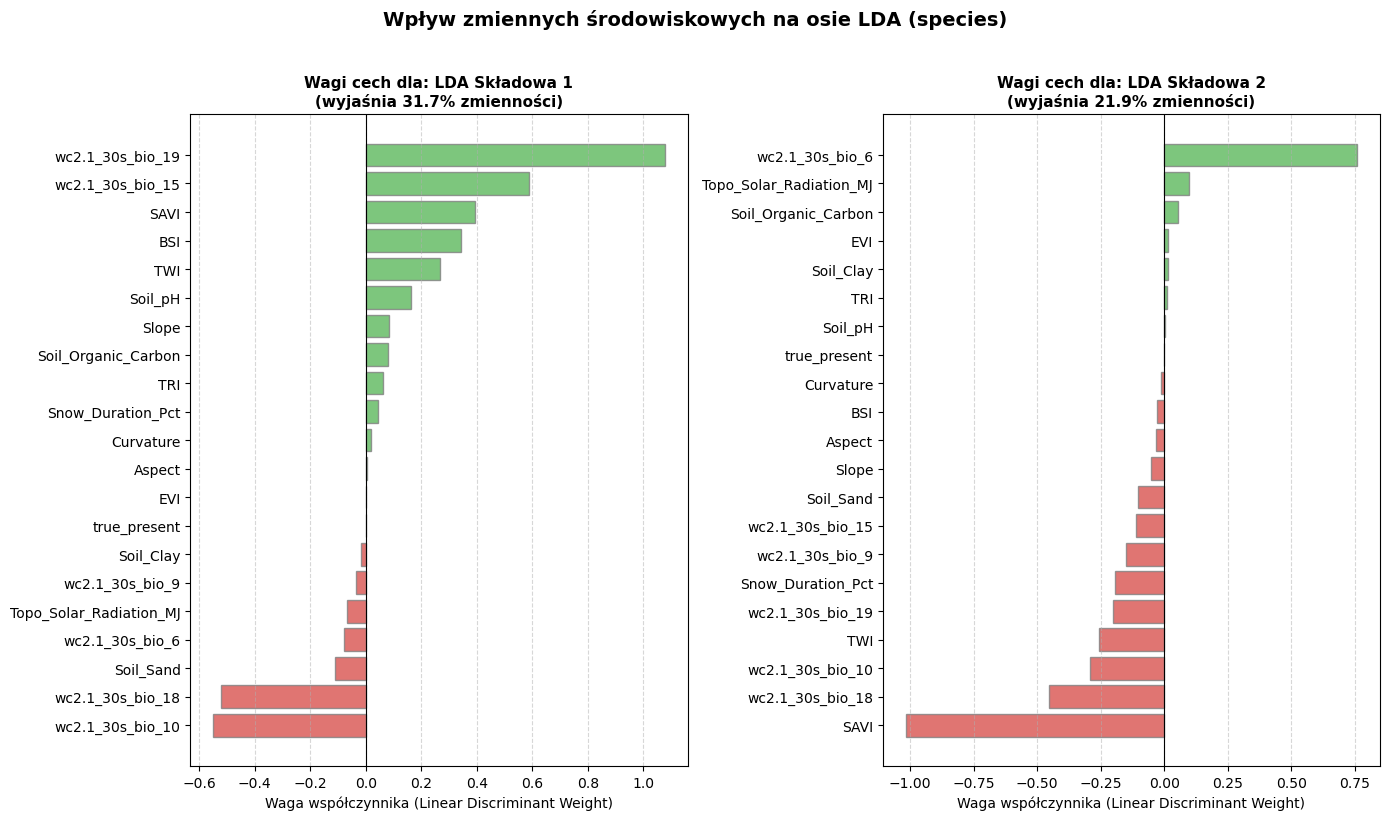

In [22]:

# =====================================================================
# WYWOŁANIE FUNKCJI
# =====================================================================
funkcje.run_lda_analysis(
    df_clean, 
    title="Analiza LDA - Różnice nisz środowiskowych gatunków alpejskich", 
    group_by_col="species"
)

# UMAP

In [23]:


# # Filtrujemy tylko kolumny numeryczne (cechy środowiskowe)
# banned_cols = ["gbifID", "species", "decimalLongitude", "decimalLatitude", "Cluster", "kmeans_cluster"]
# features_cols = [col for col in df_clean.columns if col not in banned_cols]

# X_numeric = df_clean[features_cols]
# y_species = df_clean["species"]

# # standaryzacja
# scaler = StandardScaler()
# X_scaled = scaler.fit_transform(X_numeric)

# #umap
# reducer = umap.UMAP(n_neighbors=15, min_dist=0.1, n_components=2, random_state=42)
# X_umap = reducer.fit_transform(X_scaled)

# #wizualizacja
# plt.figure(figsize=(13, 9))

# # Mapujemy każdy unikalny gatunek na punkty w nowej przestrzeni UMAP
# for species_name in y_species.unique():
#     mask = y_species == species_name
#     plt.scatter(
#         X_umap[mask, 0],
#         X_umap[mask, 1],
#         label=species_name,
#         alpha=0.6,
#         s=20,
#         edgecolors="none"
#     )

# # Opisy i formatowanie osi
# plt.title(
#     "Gatunki UMAP",
#     fontsize=14,
#     fontweight="bold",
#     pad=15
# )
# plt.xlabel("UMAP Wymiar 1", fontsize=11)
# plt.ylabel("UMAP Wymiar 2", fontsize=11)

# # Legenda wyciągnięta na bok z zachowaniem skali punktów
# plt.legend(
#     title="Badane gatunki alpejskie",
#     bbox_to_anchor=(1.02, 1),
#     loc="upper left",
#     markerscale=1.6,
#     fontsize=9
# )

# plt.tight_layout()
# plt.show()

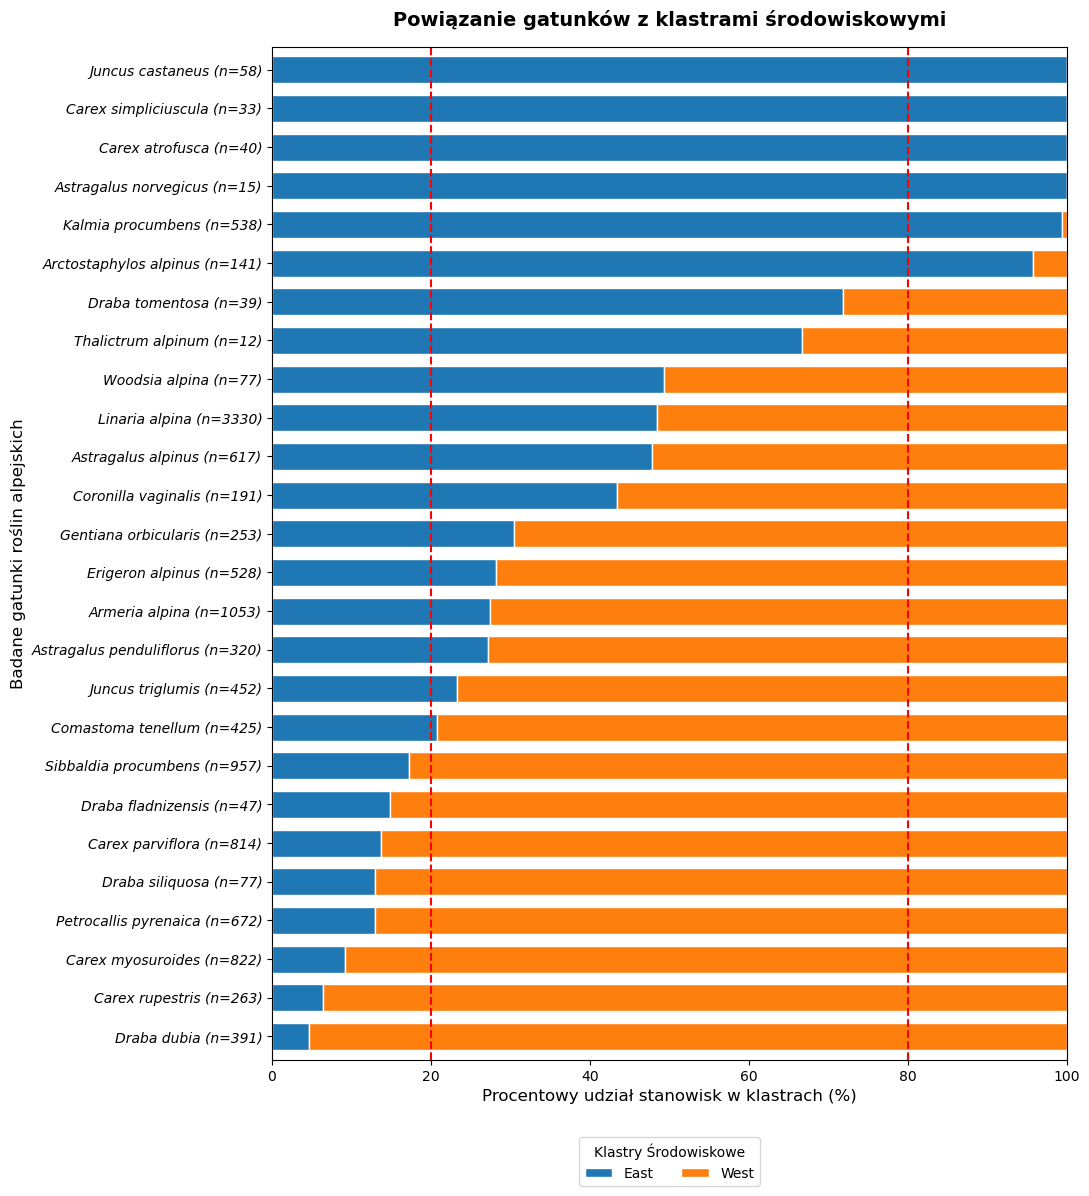

In [24]:
import matplotlib.pyplot as plt
import pandas as pd

pct_treshold =80

# Obliczamy rozkład klastrów wewnątrz każdego gatunku
sklad_counts = pd.crosstab(df_clean["species"], df_clean["Cluster"])

# Wyciągamy sumaryczną liczebność dla każdego gatunku (całkowita liczba osobników)
liczebnosci_gatunkow = sklad_counts.sum(axis=1)

#Normalizacja do procentów
sklad_gatunkowy_procent = (
    sklad_counts.div(liczebnosci_gatunkow, axis=0) * 100
)

#Tworzymy listy na dalsze analizy
gatunki_east = sklad_gatunkowy_procent[sklad_gatunkowy_procent["East"]>pct_treshold]
gatunki_east = pd.merge(gatunki_east, df_clean, on="species", how="inner")


gatunki_west = sklad_gatunkowy_procent[sklad_gatunkowy_procent["West"]>pct_treshold]
gatunki_west = pd.merge(gatunki_west, df_clean, on="species", how="inner")

# Etykiety z nazwami gatunków
nowe_etykiety = {
    gatunek: f"{gatunek} (n={liczebnosci_gatunkow[gatunek]})"
    for gatunek in sklad_gatunkowy_procent.index
}
sklad_gatunkowy_procent = sklad_gatunkowy_procent.rename(index=nowe_etykiety)


# Sortujemy według klastra "East" 
sklad_gatunkowy_procent = sklad_gatunkowy_procent.sort_values(
    by="East", ascending=True
)

# Wykres poziomy
fig, ax = plt.subplots(figsize=(11, 12))  


sklad_gatunkowy_procent.plot(
    kind="barh", stacked=True, ax=ax, edgecolor="white", width=0.7
)
#Dodanie treshold na wykresie
plt.axvline(x=pct_treshold, color="r", linestyle="--")
plt.axvline(x=(100-pct_treshold), color="r", linestyle="--")


# Stylizacja wykresu
plt.title(
    "Powiązanie gatunków z klastrami środowiskowymi",
    fontsize=14,
    fontweight="bold",
    pad=15,
)

plt.ylabel("Badane gatunki roślin alpejskich", fontsize=12)
plt.xlabel("Procentowy udział stanowisk w klastrach (%)", fontsize=12)

plt.yticks(fontsize=10, style="italic")  # Kursywa dla nazw gatunków
plt.xticks(fontsize=10)

# Konfiguracja legendy pod wykresem
plt.legend(
    title="Klastry Środowiskowe",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.07),
    ncol=2,
    frameon=True,
)

plt.xlim(0, 100)
plt.tight_layout()
plt.show()

In [25]:
gatunki_west

,species,East,West,gbifID,decimalLongitude,decimalLatitude,wc2.1_30s_bio_10,wc2.1_30s_bio_15,wc2.1_30s_bio_18,wc2.1_30s_bio_19,...,Snow_Duration_Pct,Soil_Clay,Soil_Organic_Carbon,Soil_pH,Soil_Sand,Topo_Solar_Radiation_MJ,TRI,TWI,true_present,Cluster
0,Carex myosuroides,9.124088,90.875912,6194942293,13.646944,47.500556,6.516667,23.284763,597,341,...,47.0,278.0,878.0,53.0,346.0,0.715712,2.625,8.857895,1,East
1,Carex myosuroides,9.124088,90.875912,6194831277,13.641111,47.493056,6.516666,24.474789,602,333,...,16.0,263.0,1151.0,53.0,362.0,0.851065,7.625,8.127490,1,East
2,Carex myosuroides,9.124088,90.875912,6183358443,13.027467,47.440924,5.750000,19.602217,544,339,...,60.0,259.0,988.0,53.0,355.0,0.734020,1.125,7.977353,1,East
3,Carex myosuroides,9.124088,90.875912,6183140299,13.720255,47.276043,7.000000,22.443012,588,333,...,55.0,253.0,1024.0,53.0,354.0,0.614604,2.875,8.720466,1,East
4,Carex myosuroides,9.124088,90.875912,6182842795,13.720245,47.276035,7.000000,22.443012,588,333,...,55.0,253.0,1024.0,53.0,354.0,0.614604,2.875,8.720466,1,East
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4038,Sibbaldia procumbens,17.241379,82.758621,2837159021,7.983628,46.670055,7.033333,4.789241,318,304,...,90.0,177.0,1576.0,51.0,444.0,0.816077,3.750,9.297141,1,West
4039,Sibbaldia procumbens,17.241379,82.758621,2836334981,9.813600,46.752500,8.766666,24.682871,411,228,...,81.0,174.0,807.0,50.0,479.0,0.687187,0.625,9.164354,1,East
4040,Sibbaldia procumbens,17.241379,82.758621,2835721974,10.440750,46.532145,4.383334,16.656282,223,159,...,81.0,186.0,754.0,57.0,442.0,0.737415,1.125,9.448115,1,East
4041,Sibbaldia procumbens,17.241379,82.758621,2832845881,8.392968,46.474960,5.566667,8.118270,297,252,...,78.0,213.0,1324.0,60.0,406.0,0.810268,1.375,9.145631,1,West


--- TRENOWANIE MODELU RANDOM FOREST ---

--- RAPORT KLASYFIKACJI ---
              precision    recall  f1-score   support

        East       1.00      0.99      0.99       834
        West       1.00      1.00      1.00      1599

    accuracy                           1.00      2433
   macro avg       1.00      0.99      0.99      2433
weighted avg       1.00      1.00      1.00      2433



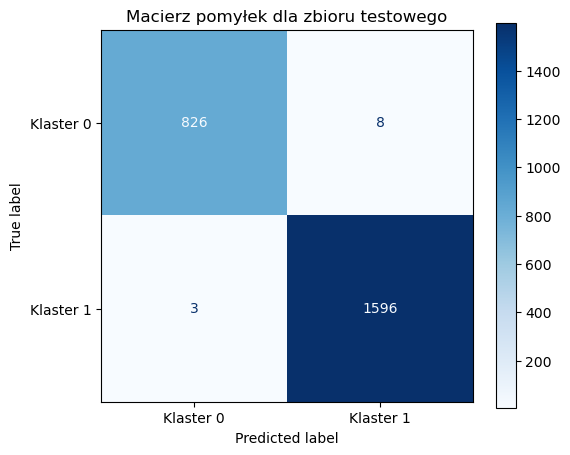

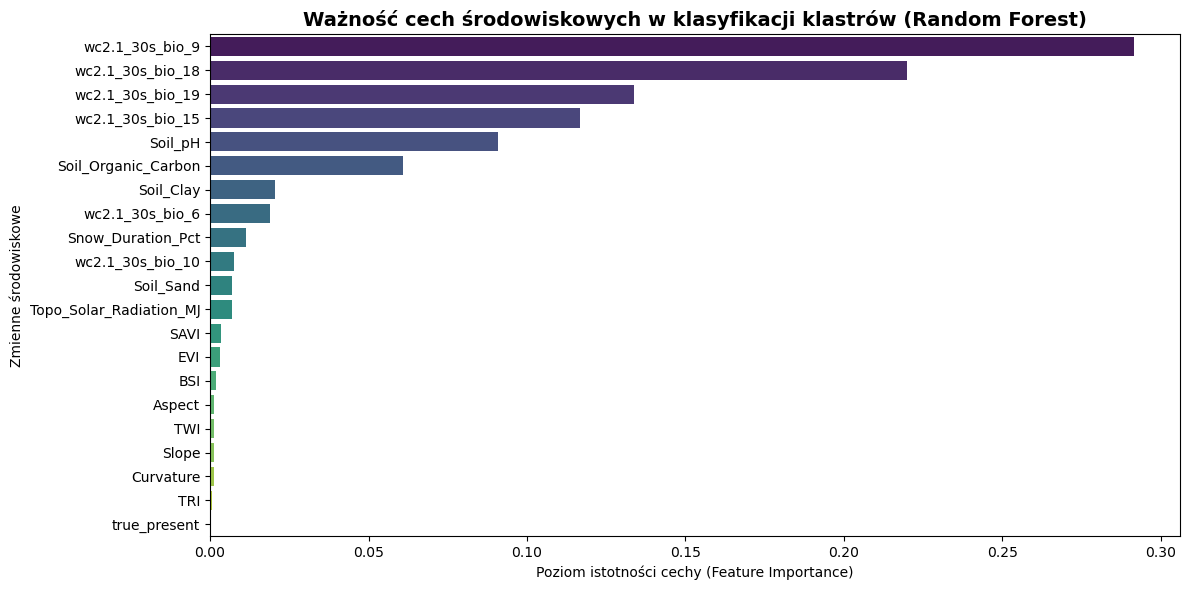

In [26]:
# Upewniamy się, że mamy czystą ramkę z cechami i etykietą klastra
# Używamy cech oryginalnych (X), a nie PCA, żeby móc zinterpretować, które realne zmienne (np. DEM, pH) są ważne!
X_rf = df_clean[features_cols]
y_rf = df_clean["Cluster"]  # Nasze klasy: 0 i 1

# Podział na zbiór treningowy i testowy (80% trening, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X_rf, y_rf, test_size=0.2, random_state=42, stratify=y_rf
)

# =====================================================================
# 2. TRENOWANIE MODELU RANDOM FOREST
# =====================================================================
print("--- TRENOWANIE MODELU RANDOM FOREST ---")
# n_estimators=100 (liczba drzew w lesie), max_depth pozwala kontrolować przeuczenie
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

# Predykcja na zbiorze testowym
y_pred = rf_model.predict(X_test)

# =====================================================================
# 3. OCENA JAKOŚCI MODELU (RAPORT I MACIERZ POMYŁEK)
# =====================================================================
print("\n--- RAPORT KLASYFIKACJI ---")
print(classification_report(y_test, y_pred))

# Wyświetlenie macierzy pomyłek (Confusion Matrix)
fig, ax = plt.subplots(figsize=(6, 5))
cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Klaster 0", "Klaster 1"])
disp.plot(cmap="Blues", ax=ax, values_format="d")
plt.title("Macierz pomyłek dla zbioru testowego")
plt.grid(False)
plt.show()

# =====================================================================
# 4. ISTOTNOŚĆ ZMIENNYCH (FEATURE IMPORTANCE)
# =====================================================================
# Wyciągamy ważność cech z modelu
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

# Tworzymy DataFrame dla łatwiejszego rysowania
df_importance = pd.DataFrame({
    "Cecha Środowiskowa": [features_cols[i] for i in indices],
    "Ważność (MDI)": [importances[i] for i in indices]
})

# Wykres słupkowy ważności cech
plt.figure(figsize=(12, 6))
sns.barplot(
    x="Ważność (MDI)", 
    y="Cecha Środowiskowa", 
    data=df_importance, 
    palette="viridis",
    hue="Cecha Środowiskowa",
    legend=False
)

plt.title("Ważność cech środowiskowych w klasyfikacji klastrów (Random Forest)", fontsize=14, fontweight="bold")
plt.xlabel("Poziom istotności cechy (Feature Importance)")
plt.ylabel("Zmienne środowiskowe")
plt.tight_layout()
plt.show()

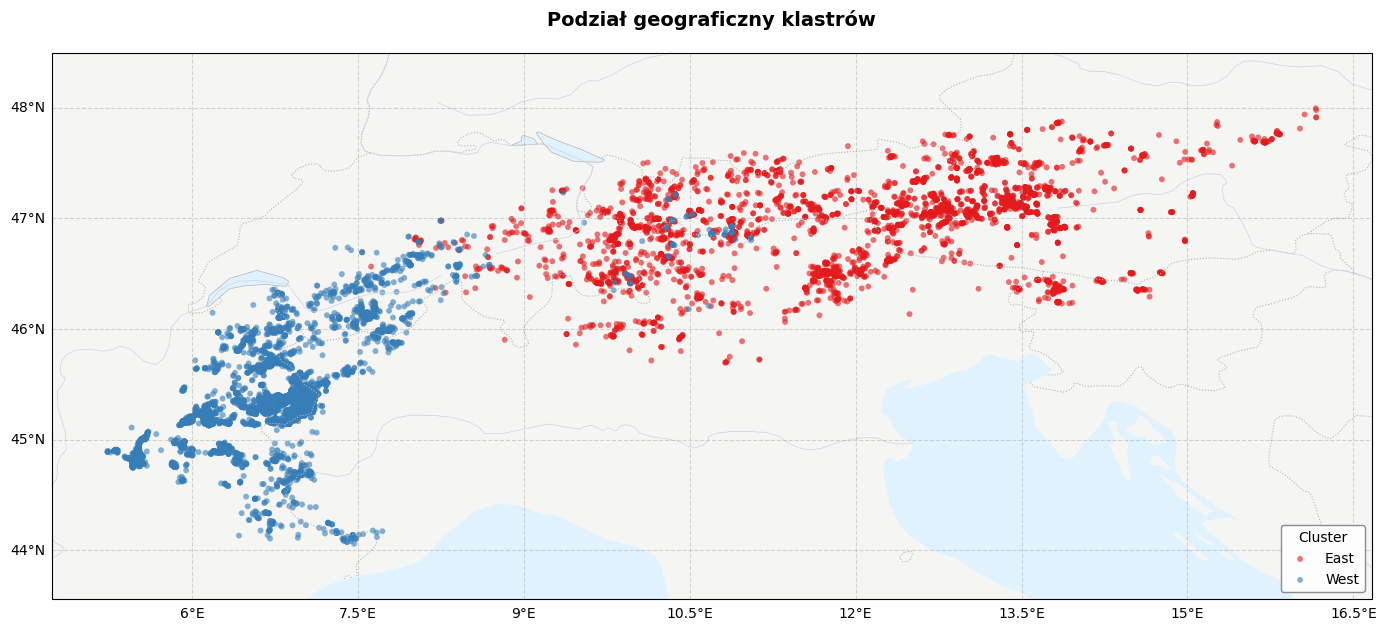

In [27]:
funkcje.df_to_map(df_clean, tytul="Podział geograficzny klastrów", col_name_to_color="Cluster")

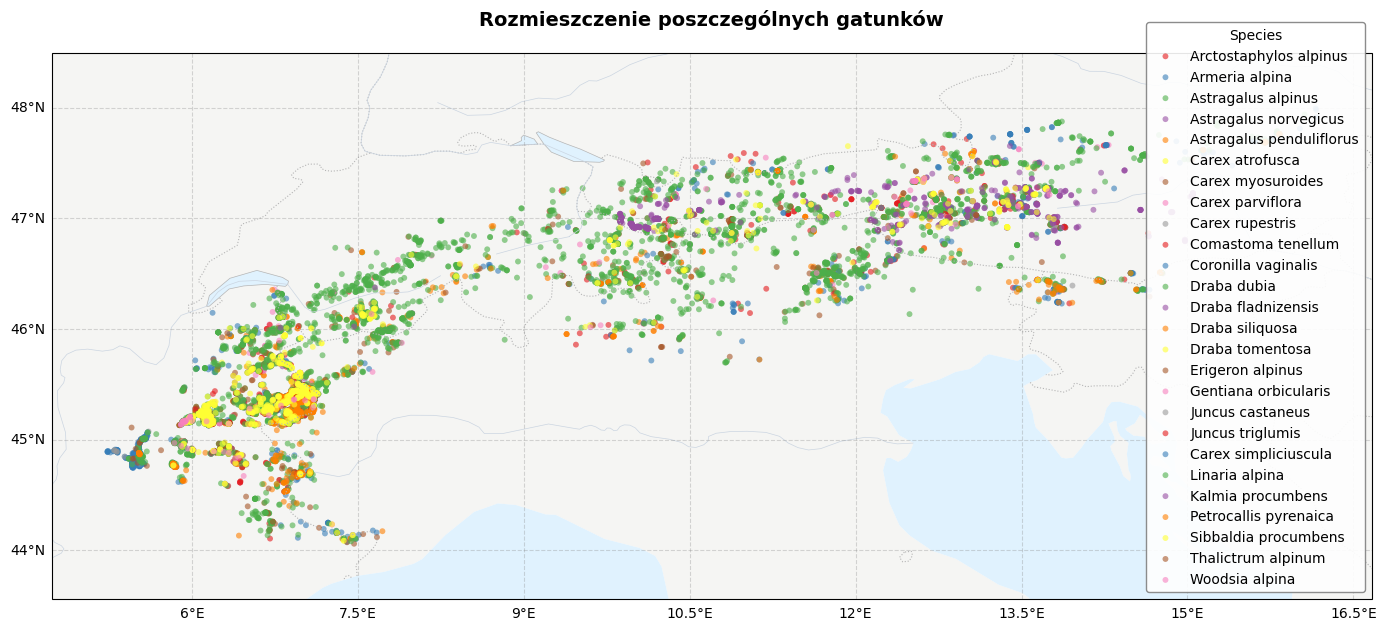

In [28]:
funkcje.df_to_map(df_clean, tytul="Rozmieszczenie poszczególnych gatunków", col_name_to_color="species")

## Gatunki WEST

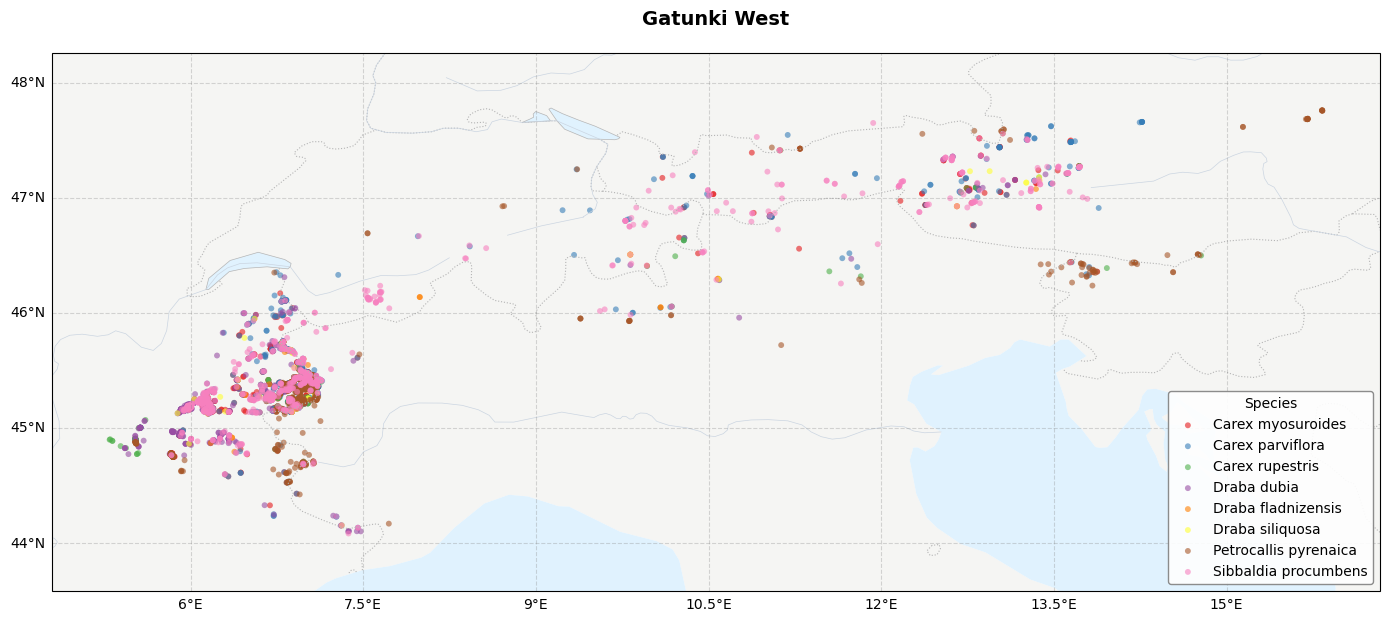

In [29]:
funkcje.df_to_map(gatunki_west,tytul="Gatunki West", col_name_to_color="species")

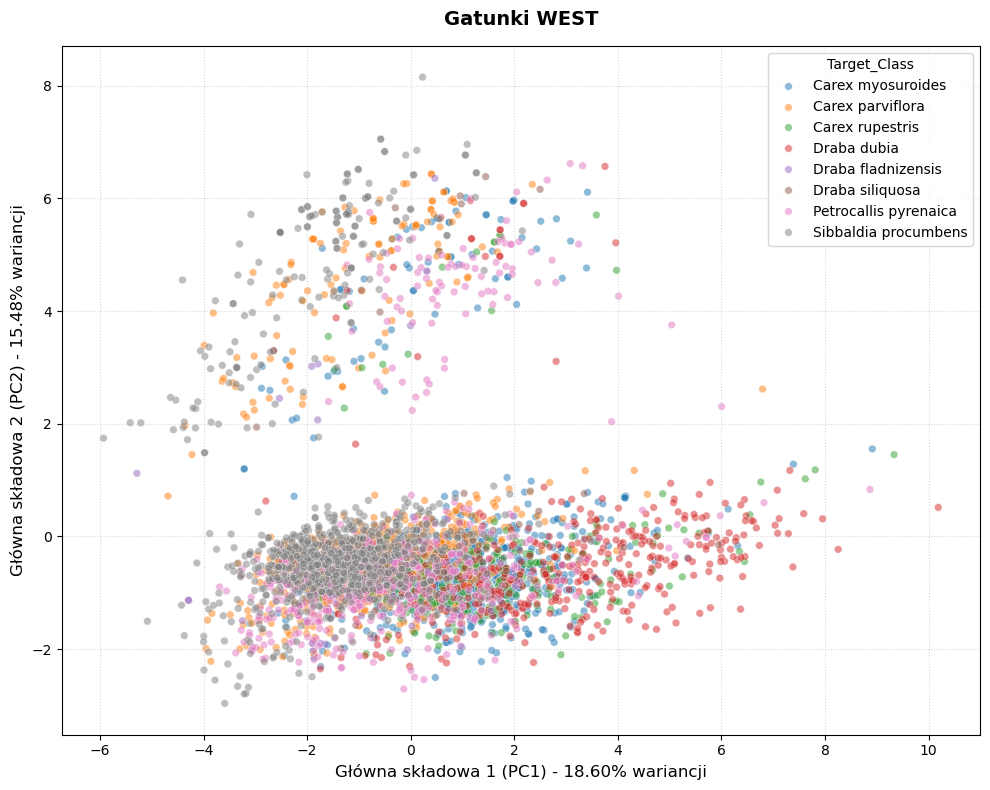

array([18.59787608, 15.48386128, 10.65888515,  8.21117784,  6.5415761 ,
        6.19099761,  5.67111858,  4.99188124,  4.52835792,  4.17060934])

In [30]:
# Uruchamiasz przekazując całe 'df', gdzie znajduje się już kolumna 'target'
df_res, var_res = funkcje.calculate_pca(gatunki_west, target_col="species",  n_components=10)

funkcje.plot_pca_space(
    df_res,
    var_res,
    hue_col="Target_Class",
    title="Gatunki WEST",
    alpha=0.5,  
    s=30,  
)
var_res

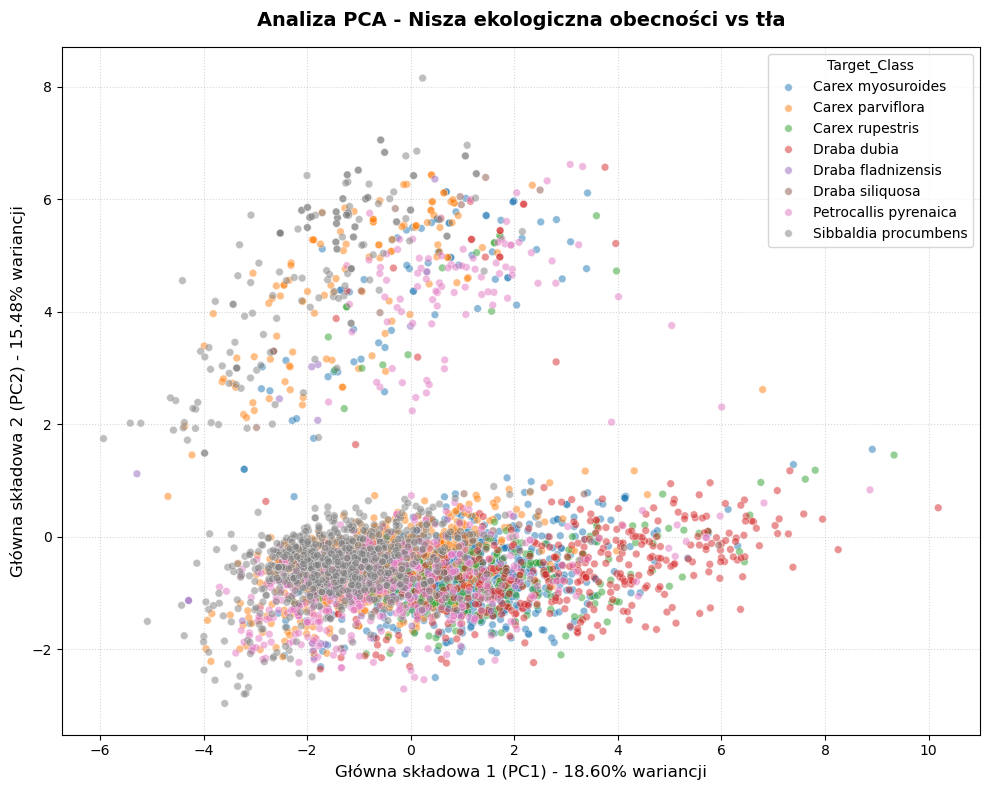

In [31]:
funkcje.plot_pca_space(
    df_res,
    var_res,
    hue_col="Target_Class",
    title="Analiza PCA - Nisza ekologiczna obecności vs tła",
    alpha=0.5,  
    s=30,  
)

## Gatunki EAST

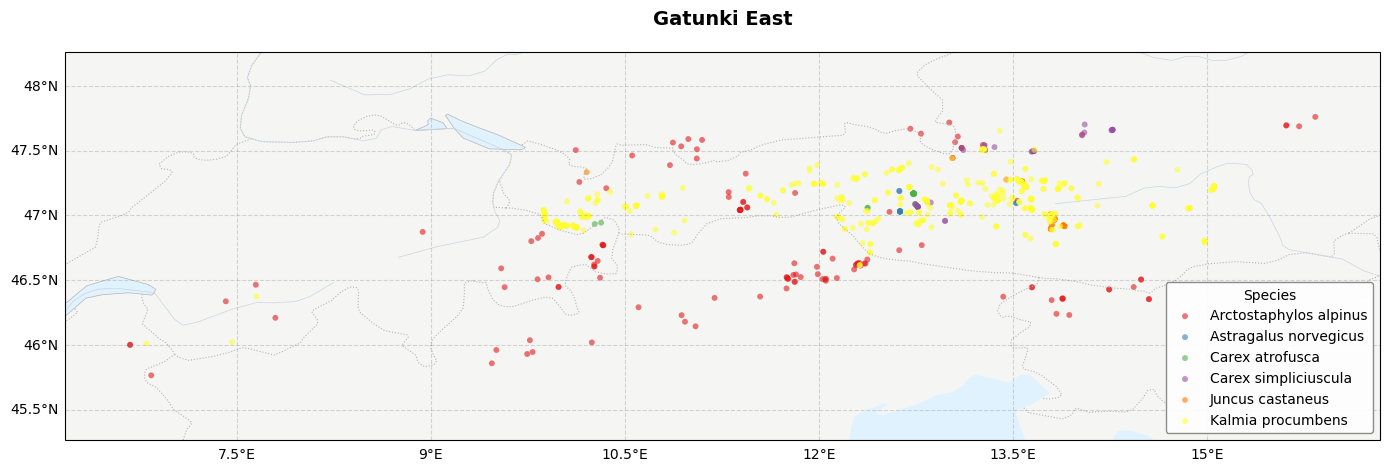

In [32]:
funkcje.df_to_map(gatunki_east, tytul="Gatunki East", col_name_to_color="species")

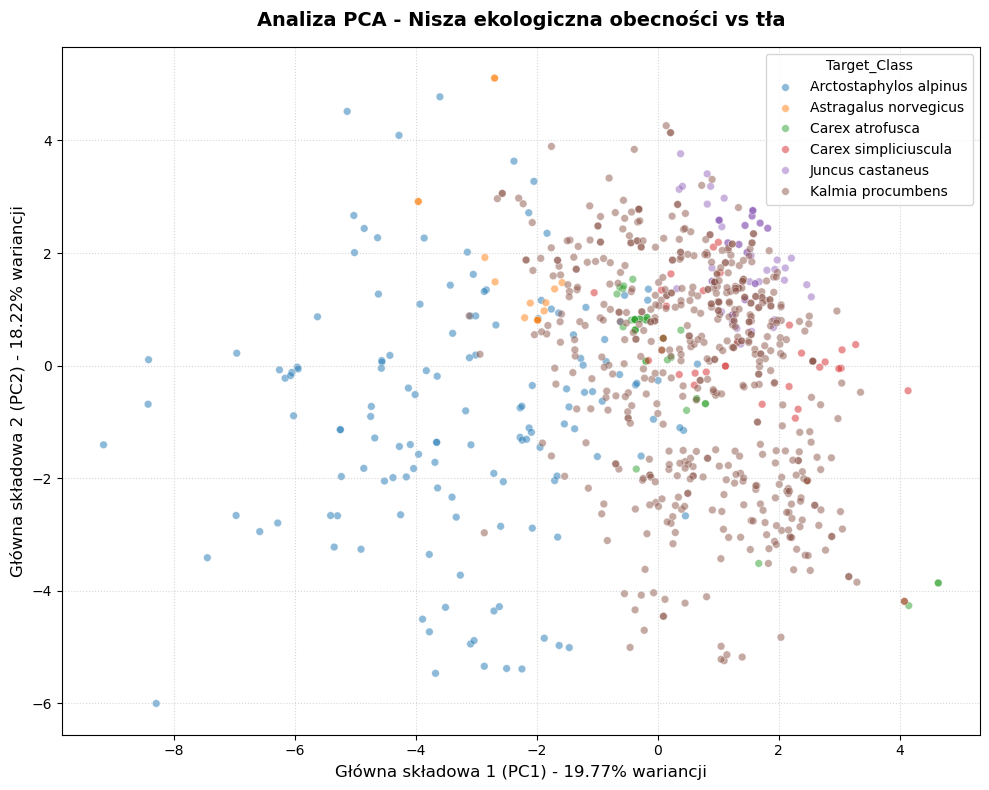

array([19.7674776 , 18.22230653, 10.37580684,  8.87700706,  6.25917643,
        6.04778206,  5.2433647 ,  4.71257655,  3.89188187,  3.54319975])

In [33]:
# Uruchamiasz przekazując całe 'df', gdzie znajduje się już kolumna 'target'
df_res, var_res = funkcje.calculate_pca(gatunki_east, target_col="species",  n_components=10)

funkcje.plot_pca_space(
    df_res,
    var_res,
    hue_col="Target_Class",
    title="Analiza PCA - Nisza ekologiczna obecności vs tła",
    alpha=0.5,  
    s=30,  
)
var_res


In [34]:
# funkcje.run_lda_analysis(gatunki_west, 
#                      title="Separacja grup za pomocą analizy LDA", 
#                      group_by_col="species",
#                      max_components_limit=2, 
#                      banned_columns=None)

# Eksport klastrów

In [35]:
df_west = df_clean[df_clean["Cluster"] == "West"]
df_west.to_csv("cluster_west.csv")
df_east = df_clean[df_clean["Cluster"] == "East"]
df_east.to_csv("cluster_east.csv")


In [36]:
gatunki_east.to_csv("gatunki_east.csv")
gatunki_west.to_csv("gatunki_west.csv")